# Módulo 6 — Zonas y mapas de características

| | |
|---|---|
| **Responde** | Devolución del anteproyecto: interfases piel-lunar, centro/periferia, mapas |
| **Código** | `zonas_y_mapas.py` (en esta misma carpeta) |
| **Recibe** | la imagen mejorada y la máscara |
| **Devuelve** | máscaras de zonas, atributos por zona, contrastes, mapas |
| **Responsable** | Lucas D'Elia |

> Las funciones se programan en `zonas_y_mapas.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: `python main.py --revisar` desde la carpeta del repo.

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m3_segmentacion import segmentacion
from modulos.m6_zonas_y_mapas import zonas_y_mapas
from modulos.m7_clasificacion_resultados import clasificacion_resultados as m7
from modulos.herramientas import graficos
from modulos.herramientas.procesamiento_completo import procesar, procesar_todos

graficos.aplicar_estilo()

## 1. Zonas

- [x] Justificar `FRACCION_CENTRO` y `ANCHO_INTERFASE` (¿fijo o proporcional al tamaño de la lesión?).
- [x] Figura para el informe: las cuatro zonas sobre una lesión.

Se usa la **máscara automática de M3**, la misma que usa el pipeline, y sólo imágenes de **entrenamiento**.

**Cómo elegir el ancho de la interfase:** se mide la mediana de V según la distancia al borde (negativa = afuera, en la piel), y cuántos píxeles tarda cada imagen en llegar al 90 % del brillo de la piel.

Píxeles hasta el 90 % de la piel: mediana 12.0 | percentil 75 19.0
Spearman entre ese ancho y el área de la lesión: 0.381
Spearman entre ese ancho y el Dice de M3: -0.285
Distancia máxima al borde de la lesión más chica: 57.0 px


PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_perfil_borde.pdf')

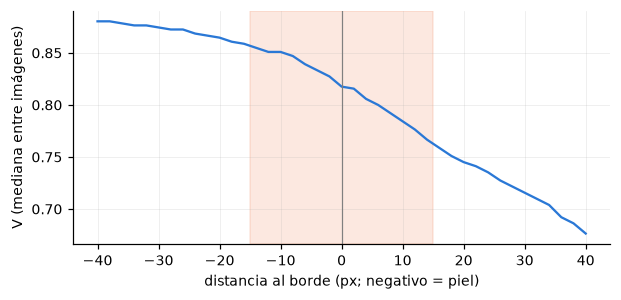

In [2]:
from scipy import ndimage as ndi, stats

casos = {}
perfiles, tamanos = [], []
radios = np.arange(-40, 41, 2)
for nombre in carga_de_datos.nombres("entrenamiento"):
    caso = carga_de_datos.cargar_caso(nombre)
    mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
    m = segmentacion.segmentar(mejorada, valida)
    casos[nombre] = (caso, mejorada, m)
    v = mejoramiento.a_hsv(mejorada)[..., 2]
    signada = np.where(m, ndi.distance_transform_edt(m), -ndi.distance_transform_edt(~m))
    perfil = [np.median(v[(signada > r - 1) & (signada <= r + 1) & valida]) if ((signada > r - 1) & (signada <= r + 1) & valida).any() else np.nan for r in radios]
    perfiles.append(perfil)
    tamanos.append({"nombre": nombre, "area": m.sum(), "distancia_maxima": ndi.distance_transform_edt(m).max(),
                    "dice": segmentacion.dice(m, caso.mascara_ref)})
perfiles, tamanos = np.array(perfiles), pd.DataFrame(tamanos)

piel, lesion = np.nanmean(perfiles[:, :3], axis=1, keepdims=True), np.nanmean(perfiles[:, -3:], axis=1, keepdims=True)
relativo = (perfiles - lesion) / np.where(piel != lesion, piel - lesion, np.nan)   # si son iguales, la imagen no cuenta
afuera = radios < 0
ancho = np.array([-radios[afuera][fila[afuera] >= 0.9].max() if (fila[afuera] >= 0.9).any() else np.nan for fila in relativo])
print("Píxeles hasta el 90 % de la piel: mediana", np.nanmedian(ancho), "| percentil 75", np.nanpercentile(ancho, 75))
print("Spearman entre ese ancho y el área de la lesión:", round(stats.spearmanr(ancho, tamanos["area"], nan_policy="omit").statistic, 3))
print("Spearman entre ese ancho y el Dice de M3:", round(stats.spearmanr(ancho, tamanos["dice"], nan_policy="omit").statistic, 3))
print("Distancia máxima al borde de la lesión más chica:", round(tamanos["distancia_maxima"].min(), 1), "px")

fig, ax = plt.subplots()
ax.plot(radios, np.nanmedian(perfiles, axis=0), color=graficos.COLOR_GRUPO["comun"])
ax.axvline(0, color="gray", linewidth=0.8)
ax.axvspan(-zonas_y_mapas.ANCHO_INTERFASE, zonas_y_mapas.ANCHO_INTERFASE, color=graficos.COLOR_GRUPO["sospechosa"], alpha=0.15)
ax.set_xlabel("distancia al borde (px; negativo = piel)"); ax.set_ylabel("V (mediana entre imágenes)")
graficos.guardar_figura(fig, "m6_perfil_borde")

**Resultado:** `ANCHO_INTERFASE` queda en **15 px fijos**. La transición tarda una mediana de 12 px y un percentil 75 de 19 px, así que 15 px cubre la mediana pero no todas las imágenes. No se llega a comer la lesión: aun la más chica tiene 57 px de distancia máxima al borde.

**Por qué fijo, si el ancho se relaciona con el área (Spearman ≈ 0,38):** con la máscara de referencia esa relación era casi nula (≈ 0,07; mediana 10 px, percentil 75 16 px). Además, el ancho crece cuando el Dice baja (Spearman ≈ −0,29). Esto sugiere que buena parte de la relación es error de M3 y no una transición más ancha en las lesiones grandes. Una imagen (IMD035) no cuenta en esta medida porque su piel y su lesión dan el mismo brillo en el perfil.

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_zonas.pdf')

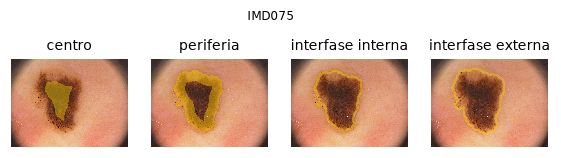

In [3]:
# Figura de las zonas sobre una lesión de tamaño típico
tamanos_ord = tamanos.sort_values("area")
nombre = tamanos_ord.iloc[len(tamanos_ord) // 2]["nombre"]
caso, mejorada, m = casos[nombre]
z = zonas_y_mapas.zonas(m)
fig, ax = plt.subplots(1, 4, figsize=(6.3, 1.6))
for a, k in zip(ax, zonas_y_mapas.ZONAS):
    graficos.superponer(a, mejorada, z[k]); a.set_title(k.replace("_", " "))
fig.suptitle(nombre, fontsize=8, y=1.02)
graficos.guardar_figura(fig, "m6_zonas")

## 2. Mapas de características

- [x] Elegir `VENTANA` y `PASO`. Mapas de 2-3 atributos en un nevo común y en un melanoma (figura clave para la defensa).
- [x] ¿Dónde se concentra la información: centro, periferia o interfase? Vincularlo con la regla ABCD.

`VENTANA` tiene un compromiso: con 15 px hay menos píxeles que celdas en una GLCM de 32 × 32, y con 51 px el mapa se aplana. La celda siguiente mide variación relativa dentro del mapa y tiempo en una muestra de 5 imágenes.

In [4]:
import time

muestra = list(casos)[::28]
filas = []
original = zonas_y_mapas.VENTANA, zonas_y_mapas.PASO
for ventana in (15, 31, 51):
    for paso in (4, 8, 16):
        zonas_y_mapas.VENTANA, zonas_y_mapas.PASO = ventana, paso
        for nombre in muestra:
            caso, mejorada, m = casos[nombre]
            t0 = time.time()
            mapa = zonas_y_mapas.mapa_caracteristica(mejoramiento.a_hsv(mejorada)[..., 2], m, "entropia")
            filas.append({"ventana": ventana, "paso": paso, "segundos": time.time() - t0,
                          "variacion relativa": np.nanstd(mapa) / np.nanmean(mapa),
                          "lesión con valor": np.isfinite(mapa[m]).mean()})
zonas_y_mapas.VENTANA, zonas_y_mapas.PASO = original
pd.DataFrame(filas).groupby(["ventana", "paso"]).median().round(3)

segundos  variacion relativa  lesión con valor
ventana paso                                                
15      4        0.964               0.131             1.000
        8        0.186               0.131             0.999
        16       0.071               0.133             0.992
31      4        0.631               0.101             1.000
        8        0.184               0.101             1.000
        16       0.075               0.102             0.998
51      4        0.677               0.078             1.000
        8        0.207               0.078             1.000
        16       0.084               0.079             1.000

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_mapas.pdf')

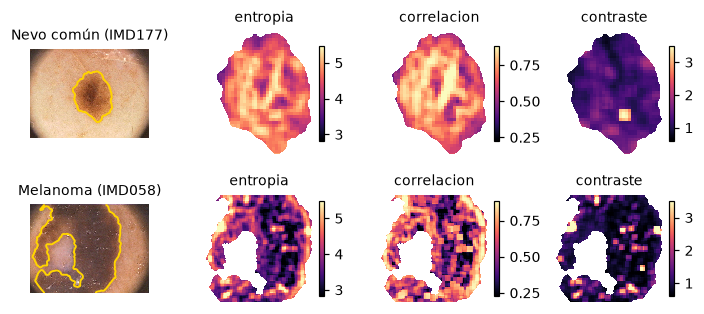

In [5]:
# Nevo común y melanoma de ENTRENAMIENTO con un área cercana a la mediana de su grupo
def de_tamano_medio(diagnostico):
    grupo = tamanos[[casos[n][0].diagnostico == diagnostico for n in tamanos["nombre"]]]
    return grupo.iloc[(grupo["area"] - grupo["area"].median()).abs().argmin()]["nombre"]

atributos = ["entropia", "correlacion", "contraste"]
elegidos = {"Nevo común": de_tamano_medio(0), "Melanoma": de_tamano_medio(2)}
mapas = {}
for titulo, nombre in elegidos.items():
    caso, mejorada, m = casos[nombre]
    v = mejoramiento.a_hsv(mejorada)[..., 2]
    mapas[titulo] = {k: zonas_y_mapas.mapa_caracteristica(v, m, k) for k in atributos}

fig, ax = plt.subplots(2, 4, figsize=(6.3, 3.0))
for fila, (titulo, nombre) in zip(ax, elegidos.items()):
    caso, mejorada, m = casos[nombre]
    graficos.mostrar(fila[0], mejorada, f"{titulo} ({nombre})")
    graficos.contorno(fila[0], m)
    for a, k in zip(fila[1:], atributos):
        rango = np.nanpercentile(np.concatenate([mapas[t][k].ravel() for t in mapas]), [2, 98])
        imagen = a.imshow(mapas[titulo][k], cmap="magma", vmin=rango[0], vmax=rango[1])
        a.set_title(k); a.set_axis_off(); a.grid(False)
        filas_m, columnas_m = np.nonzero(m)   # recorta a la lesión: el nevo es chico
        a.set_xlim(columnas_m.min() - 5, columnas_m.max() + 5); a.set_ylim(filas_m.max() + 5, filas_m.min() - 5)
        fig.colorbar(imagen, ax=a, fraction=0.04)
fig.tight_layout()
graficos.guardar_figura(fig, "m6_mapas")

In [6]:
# ¿Dónde se concentra la información? Entropía media del mapa en cada zona, por grupo
filas = []
for nombre, (caso, mejorada, m) in casos.items():
    v = mejoramiento.a_hsv(mejorada)[..., 2]
    mapa = zonas_y_mapas.mapa_caracteristica(v, m, "entropia")
    z = zonas_y_mapas.zonas(m)
    filas.append({"sospechosa": caso.sospechosa, "centro": np.nanmean(mapa[z["centro"]]), "periferia": np.nanmean(mapa[z["periferia"]]),
                  "interfase interna": np.nanmean(mapa[z["interfase_interna"]])})
por_zona = pd.DataFrame(filas)
print(por_zona.groupby("sospechosa").median().round(3).to_string())
print({k: round(m7.auc(por_zona[k], por_zona["sospechosa"]), 3) for k in ("centro", "periferia", "interfase interna")})

            centro  periferia  interfase interna
sospechosa                                      
False        4.402      4.305              4.163
True         4.309      4.395              4.327
{'centro': 0.431, 'periferia': 0.559, 'interfase interna': 0.61}


**`VENTANA` y `PASO`:** se eligen **31 px** y **8 px**. Con 15 px la GLCM queda casi vacía, con 51 px el mapa se aplana (variación relativa 0,08 contra 0,10), y un paso de 8 tarda unos 0,2 s por imagen, suficiente para usarlo en la interfaz.

**¿Dónde se concentra la información?** En los nevos comunes la entropía **baja** de adentro hacia afuera (4,40 en el centro → 4,31 en la periferia → 4,16 en la interfase interna). En las sospechosas no muestra esa caída (4,31 → 4,40 → 4,33). Las zonas separan en sentidos opuestos: en las sospechosas hay **menos** entropía en el centro (AUC 0,43, o sea 0,57 invertido) y **más** en la interfase interna (AUC 0,61). Cada una por sí sola separa poco, pero esto apoya mirar la lesión por zonas: un único número global promedia comportamientos opuestos.

Los mapas de arriba son dos ejemplos para ilustrarlo, no una prueba. En el melanoma (IMD058, Dice 0,89, cerca de la mediana de los melanomas) la máscara deja afuera una zona central clara, y por eso el mapa tiene ese hueco.

## 3. Contrastes entre zonas → términos candidatos del TDS

- [x] Boxplots de cada contraste por grupo (común vs. sospechosa) en entrenamiento.
- [x] Proponer a M7 los 1-3 mejores términos (`TERMINOS_EXTRA`).

**El signo importa:** `tds_extendido` **suma** cada término, así que un contraste con AUC < 0,5 empeoraría el TDS. Por eso las restas están definidas como **periferia − centro** y **piel − lesión**.

También se prueba si cambiar `FRACCION_CENTRO` o `ANCHO_INTERFASE` cambia algo.

In [7]:
original = zonas_y_mapas.FRACCION_CENTRO, zonas_y_mapas.ANCHO_INTERFASE
variantes = [(0.5, 15), (0.3, 15), (0.7, 15), (0.5, 5), (0.5, 30)]
contrastes = {}
for fraccion, ancho in variantes:
    zonas_y_mapas.FRACCION_CENTRO, zonas_y_mapas.ANCHO_INTERFASE = fraccion, ancho
    contrastes[(fraccion, ancho)] = pd.DataFrame(
        [zonas_y_mapas.contrastes_entre_zonas(zonas_y_mapas.atributos_por_zona(mejorada, m)) for _, mejorada, m in casos.values()])
zonas_y_mapas.FRACCION_CENTRO, zonas_y_mapas.ANCHO_INTERFASE = original
sospechosa = np.array([caso.sospechosa for caso, *_ in casos.values()])

auc = pd.DataFrame({f"centro {f}, ancho {a}": {k: m7.auc(t[k], sospechosa) for k in t.columns} for (f, a), t in contrastes.items()})
auc = auc.sort_values(auc.columns[0], ascending=False)
elegida = contrastes[original]
print("Frecuencia de NaN:", int(elegida.isna().sum().sum()))
# ¿Los mejores aportan algo distinto, o miden lo oscura que es la lesión o cuánto falló M3?
extras = pd.DataFrame([{"V lesión": np.median(mejoramiento.a_hsv(mejorada)[..., 2][m]), "Dice": segmentacion.dice(m, caso.mascara_ref)} for caso, mejorada, m in casos.values()])
candidatos = pd.concat([elegida[["periferia_vs_centro_S", "interfase_V", "interfase_S"]], extras], axis=1)
print(candidatos.corr("spearman").round(2).to_string())
print("AUC de lo oscura que es la lesión (-V lesión):", round(m7.auc(-extras["V lesión"], sospechosa), 3))
tabla_auc = auc.iloc[:, [0]].rename(columns={auc.columns[0]: "AUC"}).rename_axis("contraste").reset_index()
tabla_auc["contraste"] = tabla_auc["contraste"].str.replace("_", " ")
graficos.guardar_tabla(tabla_auc, "m6_contrastes", decimales=2)
auc.round(3)

Frecuencia de NaN: 0


                       periferia_vs_centro_S  interfase_V  interfase_S  V lesión  Dice
periferia_vs_centro_S                   1.00         0.68         0.08     -0.74  0.18
interfase_V                             0.68         1.00         0.09     -0.77  0.04
interfase_S                             0.08         0.09         1.00     -0.14 -0.56
V lesión                               -0.74        -0.77        -0.14      1.00 -0.11
Dice                                    0.18         0.04        -0.56     -0.11  1.00
AUC de lo oscura que es la lesión (-V lesión): 0.754


,"centro 0.5, ancho 15","centro 0.3, ancho 15","centro 0.7, ancho 15","centro 0.5, ancho 5","centro 0.5, ancho 30"
periferia_vs_centro_S,0.764,0.786,0.742,0.764,0.764
interfase_V,0.741,0.741,0.741,0.738,0.722
interfase_S,0.685,0.685,0.685,0.645,0.733
periferia_vs_centro_entropia,0.618,0.653,0.602,0.618,0.618
periferia_vs_centro_H,0.587,0.617,0.553,0.587,0.587
periferia_vs_centro_contraste,0.559,0.583,0.551,0.559,0.559
interfase_contraste,0.535,0.535,0.535,0.493,0.580
periferia_vs_centro_V,0.526,0.547,0.510,0.526,0.526
interfase_entropia,0.426,0.426,0.426,0.429,0.469
interfase_H,0.421,0.421,0.421,0.394,0.442


PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/TPF/TPI/PSIB2026Q2-TPI-Grupo02-CassanoNieto-DElia-Ortega/informe/figuras/m6_contrastes.pdf')

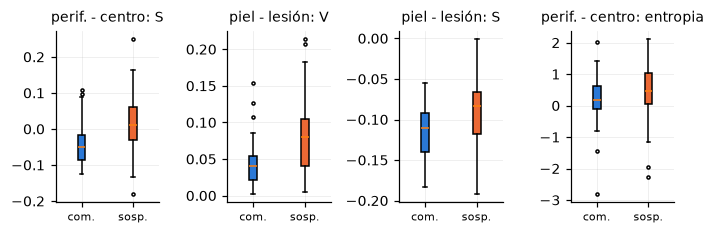

In [8]:
mejores = list(auc.index[:4])
fig, ax = plt.subplots(1, 4, figsize=(6.3, 2.2))
for a, k in zip(ax, mejores):
    cajas = a.boxplot([elegida.loc[~sospechosa, k], elegida.loc[sospechosa, k]], tick_labels=["com.", "sosp."], patch_artist=True, flierprops={"markersize": 2})
    cajas["boxes"][0].set_facecolor(graficos.COLOR_GRUPO["comun"]); cajas["boxes"][1].set_facecolor(graficos.COLOR_GRUPO["sospechosa"])
    a.set_title(k.replace("periferia_vs_centro_", "perif. - centro: ").replace("interfase_", "piel - lesión: ")); a.tick_params(axis="x", labelsize=7)
fig.tight_layout()
graficos.guardar_figura(fig, "m6_contrastes")

**Términos elegidos para M7:** `TERMINOS_EXTRA = ["zona_periferia_vs_centro_S", "zona_interfase_S"]`, con AUC 0,76 y 0,69 en entrenamiento. Casi no se correlacionan entre sí (ρ ≈ 0,08), así que cada uno aporta algo distinto. La elección quedó fijada antes de mirar el conjunto de prueba. En prueba dan 0,71 y 0,60 (ver el cuaderno de M7).

**Por qué no `interfase_V`, aunque es el segundo en AUC (0,74):** se correlaciona con `periferia_vs_centro_S` (ρ ≈ 0,68) y con el brillo de la lesión (ρ ≈ −0,77), así que agrega poco. Con la máscara de referencia su AUC era 0,60.

**Cuidado al usarlos:**
- `periferia_vs_centro_S` también sigue al brillo de la lesión (ρ ≈ −0,74), y ese brillo solo ya separa con AUC 0,75. Hay que comprobar que le sume algo al TDS una vez que esté el criterio C de M4, porque su AUC solo no lo demuestra.
- `interfase_S` baja cuando M3 acierta más (ρ ≈ −0,56 con el Dice), así que en parte mide errores de segmentación. No es sólo eso: con la máscara de referencia su AUC también era 0,68.
- Se miraron 10 contrastes sobre 140 imágenes: el AUC del elegido está algo inflado, y sólo la evaluación en prueba lo confirma.
- `FRACCION_CENTRO` mueve `periferia_vs_centro_S` entre 0,74 y 0,79, y `ANCHO_INTERFASE` mueve `interfase_S` entre 0,65 y 0,73. No se ajustan para maximizar esos valores: se quedan los de la sección 1 para no inflar más el resultado.
- Esto muestra asociación, no causa. El porqué clínico de que la periferia esté más saturada que el centro en las sospechosas **queda para discutir** en el marco teórico: no se puede afirmar sólo con este análisis.